# Fuzzy C-Means Clustering

Computer Science Dept, Ferdowsi University of Mashhad

## Where this page sits

Every method in this section so far returns a **hard** partition: K-means,
K-medoids, hierarchical clustering, spectral clustering and DBSCAN each answer
the question "which cluster does this point belong to?" with one label. For a
point exactly halfway between two groups the answer is still one label, chosen
by a fraction of a unit of distance, and the information that the point was
ambiguous is thrown away.

Fuzzy C-means (FCM; Dunn 1973, Bezdek 1981) keeps it. Instead of a label, each
point gets a **membership degree** in every cluster, a number in $[0, 1]$, and
the degrees of one point sum to one. A point in the middle of a gap may belong
$0.55$ to one cluster and $0.45$ to the other; a point deep inside a cluster
belongs $0.99$ to it. K-means is the limiting case in which every membership is
forced to $0$ or $1$.

### What you should be able to do at the end

* write the FCM objective and derive its two update equations;
* explain what the fuzzifier $m$ does, including the limits $m \to 1$ and
  $m \to \infty$;
* implement FCM from scratch and check that the objective decreases at every
  iteration;
* read a membership matrix, pick out the ambiguous points, and say when a soft
  partition is more useful than a hard one;
* state what FCM shares with K-means - and therefore which of K-means'
  weaknesses it does *not* repair.

## 1. A partition becomes a matrix

Let $X = \{x_1, \dots, x_N\} \subset \mathbb{R}^d$ and let $c$ be the number
of clusters. A **fuzzy $c$-partition** is a matrix
$U = (u_{ij}) \in [0,1]^{N \times c}$ with

$$
\sum_{j=1}^{c} u_{ij} = 1 \quad \text{for every point } i,
\qquad
0 < \sum_{i=1}^{N} u_{ij} < N \quad \text{for every cluster } j .
$$

The first condition says the memberships of a point are shares of one whole;
the second says no cluster is empty and no cluster takes everything. A hard
partition is the special case $u_{ij} \in \{0, 1\}$, and then $U$ is just the
indicator matrix of the labels.

Two numbers summarise a soft partition and are worth remembering:

* the **partition coefficient** $\mathrm{PC} = \frac{1}{N}\sum_{i,j} u_{ij}^2$,
  which is $1$ for a hard partition and $1/c$ when every point is equally
  undecided;
* the **partition entropy** $\mathrm{PE} = -\frac{1}{N}\sum_{i,j} u_{ij}\log u_{ij}$,
  which moves in the opposite direction.

Neither is a substitute for looking at the memberships, but both turn "how
fuzzy is this clustering?" into a number.

## 2. The objective and its two updates

FCM minimises a weighted within-cluster scatter in which every point is counted
in every cluster, with weight equal to its membership:

$$
J_m(U, C) = \sum_{i=1}^{N} \sum_{j=1}^{c} u_{ij}^{m} \, \lVert x_i - c_j \rVert^2 ,
\qquad m > 1 .
$$

The exponent $m$ is the **fuzzifier**. It is not fitted; it is chosen, and
Section 4 is about how. For $m \to 1$ the objective approaches the K-means
criterion, because any membership strictly between $0$ and $1$ becomes
infinitely expensive compared with a hard one. For $m \to \infty$ the
membership term flattens out and every point ends up with $u_{ij} = 1/c$: the
fuzziest possible partition, and a useless one.

Minimising $J_m$ under the constraint $\sum_j u_{ij} = 1$ is a constrained
problem, solved by Lagrange multipliers. The stationarity conditions give two
equations that are each the other's input:

$$
u_{ij} = \left( \sum_{k=1}^{c}
\left( \frac{\lVert x_i - c_j \rVert}{\lVert x_i - c_k \rVert}
\right)^{\frac{2}{m-1}} \right)^{-1},
\qquad
c_j = \frac{\sum_{i=1}^{N} u_{ij}^{m} x_i}{\sum_{i=1}^{N} u_{ij}^{m}} .
$$

Read them side by side with K-means:

* the centre is still a weighted mean, but the weight of $x_i$ is
  $u_{ij}^m$ instead of the indicator $\mathbb{1}[\text{label}(i)=j]$;
* the membership is no longer "nearest centre wins" but a **softmax-like
  ratio of distances**: if $x_i$ is much closer to $c_j$ than to the other
  centres, $u_{ij}$ is close to $1$; if two centres are equidistant, the two
  memberships are equal, and the exponent $2/(m-1)$ controls how quickly the
  ratio saturates.

The algorithm alternates the two equations.

```
initialise U (rows on the simplex)
repeat:
    c_j = weighted mean of X with weights u_ij^m
    u_ij = 1 / sum_k (d_ij / d_ik)^(2/(m-1))
until max |U_new - U_old| < tol
```

Each step decreases $J_m$ and $J_m$ is bounded below, so the iteration
converges - to a local minimum, exactly as K-means does, from which it follows
that FCM needs several restarts or a good initialisation. The usual
initialisation is a hard K-means run, which starts the iteration from a
sensible corner of the simplex rather than from random shares.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score


def fuzzy_c_means(X, c, m=2.0, n_iter=200, tol=1e-7, seed=0):
    """Alternate the two stationarity equations; return centres, U and J_m history."""
    rng = np.random.default_rng(seed)
    n = len(X)
    U = rng.random((n, c))
    U /= U.sum(axis=1, keepdims=True)

    history, previous = [], None
    for iteration in range(n_iter):
        Um = U ** m
        centres = (Um.T @ X) / Um.sum(axis=0)[:, None]

        distances = np.sqrt(((X[:, None, :] - centres[None, :, :]) ** 2).sum(-1))
        distances = np.maximum(distances, 1e-12)
        inv = distances ** (-2.0 / (m - 1))
        U = inv / inv.sum(axis=1, keepdims=True)

        history.append(float((Um * distances ** 2).sum()))
        if previous is not None and np.max(np.abs(U - previous)) < tol:
            break
        previous = U.copy()

    return centres, U, np.array(history), iteration + 1


def partition_coefficient(U):
    return float((U ** 2).sum() / len(U))


## 3. A first run, and the points K-means had to decide

Three well-separated Gaussian blobs are the easy case, deliberately: the two
methods should agree, and the interesting part is the small set of points near
the boundary, where FCM reports a split membership and K-means reports a label
chosen by a rounding.

The code below runs both, prints how many points have a maximum membership
below $0.7$ (the genuinely ambiguous ones), and shows the memberships of the
eight most undecided points.

converged in 22 iterations, objective 4519.8 -> 699.8
partition coefficient (1 = hard): 0.821
points with max membership < 0.7: 42
ARI with the true labels: FCM 0.880, K-means 0.873

most undecided points
 point               x    u_1    u_2    u_3  K-means
   267  ( 10.69,  2.70)   0.49   0.02   0.49        1
   303  ( 10.88,  2.66)   0.50   0.02   0.47        1
   227  ( 10.63,  2.75)   0.47   0.02   0.51        1
   293  ( 11.51,  2.78)   0.46   0.03   0.51        1
   148  ( 10.71,  2.78)   0.46   0.02   0.52        1
    18  (  8.67,  2.65)   0.53   0.02   0.45        2
    77  ( 10.98,  2.56)   0.53   0.02   0.44        2
    52  ( 10.34,  2.83)   0.44   0.02   0.55        1


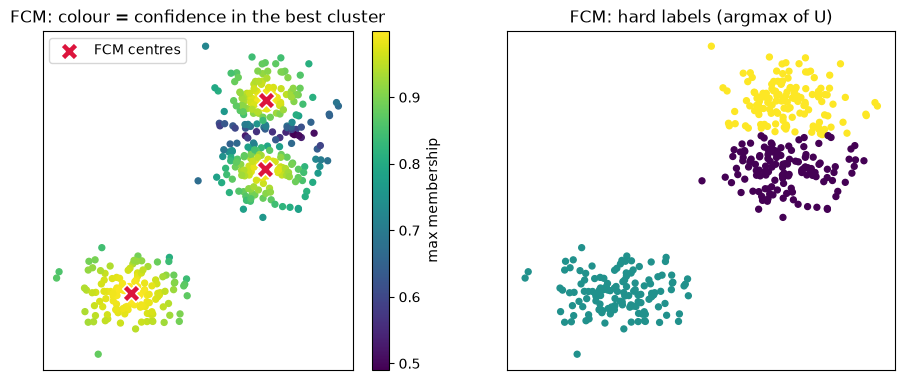

In [2]:
X, y = make_blobs(n_samples=400, centers=3, cluster_std=1.1, random_state=4)

centres, U, history, n_steps = fuzzy_c_means(X, c=3, m=2.0)
fcm_labels = U.argmax(axis=1)
kmeans_labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)

print(f"converged in {n_steps} iterations, objective {history[0]:.1f} -> {history[-1]:.1f}")
print(f"partition coefficient (1 = hard): {partition_coefficient(U):.3f}")
print(f"points with max membership < 0.7: {(U.max(axis=1) < 0.7).sum()}")
print(f"ARI with the true labels: FCM {adjusted_rand_score(y, fcm_labels):.3f}, "
      f"K-means {adjusted_rand_score(y, kmeans_labels):.3f}")

uncertain = np.argsort(U.max(axis=1))[:8]
print("\nmost undecided points")
print(f"{'point':>6}  {'x':>14}  {'u_1':>5}  {'u_2':>5}  {'u_3':>5}  {'K-means':>7}")
for i in uncertain:
    print(f"{i:6d}  ({X[i, 0]:6.2f},{X[i, 1]:6.2f})"
          f"  {U[i, 0]:5.2f}  {U[i, 1]:5.2f}  {U[i, 2]:5.2f}  {kmeans_labels[i]:7d}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sc = axes[0].scatter(X[:, 0], X[:, 1], c=U.max(axis=1), cmap="viridis", s=18)
axes[0].scatter(centres[:, 0], centres[:, 1], c="crimson", marker="X", s=160,
                edgecolor="white", linewidth=1.2, label="FCM centres")
axes[0].set_title("FCM: colour = confidence in the best cluster")
axes[0].legend(loc="upper left")
fig.colorbar(sc, ax=axes[0], label="max membership")
axes[1].scatter(X[:, 0], X[:, 1], c=fcm_labels, cmap="viridis", s=18)
axes[1].set_title("FCM: hard labels (argmax of U)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Two things are worth taking from the output.

First, the hard clustering lands within a hundredth of K-means' ARI, which is
the sanity check: on easy data the soft method should not invent structure.
(The cluster *numbers* are arbitrary in both methods and are not aligned with
each other, so only the partitions can be compared, not the labels.) Second,
the membership column tells a different story from the labels. The points
printed are precisely the ones in the corridor between two of the blobs; their
membership vectors are near $(0.5, 0.02, 0.5)$, while the labels column forces
them into one group of the hard partition. If the application is a decision,
the label is what you need; if it is an expert reading a segmentation, or a
downstream model that should know how strongly to trust the assignment, the
membership vector is the more honest input.

The colour scale in the left panel is that information in one picture: bright
points are the cores of the clusters, dark points are the borderline.

## 4. What the fuzzifier does

$m$ controls how much a slightly better fit is worth. It is usually set
between $1.5$ and $2.5$, with $2$ the default in most software, and the reason
is a bias-variance trade-off of a familiar kind:

* small $m$ (near $1$) - memberships saturate quickly, so the result is nearly
  hard and inherits K-means' fragility: a point is claimed by one cluster even
  when it is equidistant. Numerically the iteration becomes stiff as
  $m \to 1$.
* large $m$ - memberships spread towards $1/c$, clusters overlap more than the
  data warrants, and the centres drift towards the overall mean.
* $m \to 1$ and $m \to \infty$ are the two limits discussed in Section 2.

The experiment measures both limits on the same three blobs.

    m      PC   ambiguous         J_m   iters
  1.1   0.993       0.8%       852.1      21
  1.3   0.971       2.0%       842.8      22
  1.6   0.921       4.2%       803.8      21
  2.0   0.821      10.5%       699.8      22
  2.5   0.692      20.8%       525.4      24
  3.5   0.522      63.0%       236.1      30
  6.0   0.388      99.2%        20.1      44


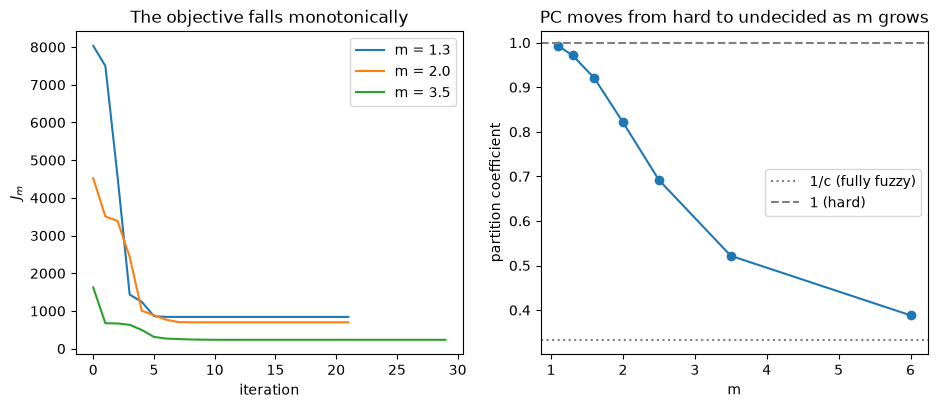

In [3]:
m_values = [1.1, 1.3, 1.6, 2.0, 2.5, 3.5, 6.0]
rows = []
for m in m_values:
    centres_m, U_m, history_m, steps_m = fuzzy_c_means(X, c=3, m=m)
    rows.append((m, partition_coefficient(U_m), float((U_m.max(axis=1) < 0.7).mean()),
                 history_m[-1], steps_m))

print(f"{'m':>5}  {'PC':>6}  {'ambiguous':>10}  {'J_m':>10}  {'iters':>6}")
for m, pc, amb, objective, steps_m in rows:
    print(f"{m:5.1f}  {pc:6.3f}  {amb:9.1%}  {objective:10.1f}  {steps_m:6d}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for m in [1.3, 2.0, 3.5]:
    _, _, hist, _ = fuzzy_c_means(X, c=3, m=m)
    axes[0].plot(hist, label=f"m = {m}")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"$J_m$")
axes[0].set_title("The objective falls monotonically")
axes[0].legend()

axes[1].plot([r[0] for r in rows], [r[1] for r in rows], marker="o")
axes[1].axhline(1 / 3, color="gray", linestyle=":", label="1/c (fully fuzzy)")
axes[1].axhline(1.0, color="gray", linestyle="--", label="1 (hard)")
axes[1].set_xlabel("m")
axes[1].set_ylabel("partition coefficient")
axes[1].set_title("PC moves from hard to undecided as m grows")
axes[1].legend()
plt.show()

The curves and the table say the same thing from two sides. At $m = 1.3$ the
partition coefficient is close to $1$ and only 2% of the points are
ambiguous: the method has quietly become K-means. At $m = 3.5$ the coefficient
has fallen to about $0.52$, and 63% of the points have no clear winner, and
$J_m$ is no longer comparable with the values at other $m$ - $J_m$ depends on
$m$, so it cannot be used to choose $m$ by minimisation. That is why the choice is a modelling
decision, not an optimisation: pick the $m$ at which the memberships are
informative for the question at hand, and check that the cluster centres do not
move much when $m$ changes slightly.

The left panel is a diagnostic worth running every time: a monotone decreasing
$J_m$ confirms the implementation is the one from Section 2. A rise means a bug
in an update equation - usually a transposed $U$ or a forgotten exponent.

## 5. What FCM does and does not repair

FCM is a *centroid-based* method. The centre update is still a mean, the
distance is still Euclidean, and the objective still sums squared distances.
Everything K-means assumes, FCM assumes too:

* clusters are roughly convex and of comparable spread - the two-moons failure
  of [the DBSCAN page](DBSCAN.ipynb) happens here as well, only now the
  confusion is visible as memberships near $0.5$ instead of as a wrong label;
* $c$ must be given in advance;
* the squared distance gives outliers a large influence, and an outlier is
  spread over all clusters rather than rejected - soft assignment is *not*
  noise handling.

What it adds is a calibrated notion of ambiguity, and that is genuinely useful
where the boundary is the object of study rather than an inconvenience:

* image segmentation, where a pixel on the boundary between two tissues has a
  meaningful partial volume;
* medical and remote-sensing images, where the membership map is inspected
  directly and a hard boundary would be a false precision;
* as a soft front end to a downstream model that weights its inputs by
  confidence.

If outliers must be rejected rather than shared, the usual extension is
**possibilistic c-means** (Krishnapuram and Keller, 1993), which drops the
"memberships sum to one" constraint so that a point can have low membership
everywhere; the price is that clusters can become coincident and the method
needs a good initialisation.

## Summary

* A fuzzy partition assigns each point a membership vector on the simplex
  instead of a label; hard clustering is the corner case.
* FCM minimises $J_m = \sum_{i,j} u_{ij}^m \lVert x_i - c_j \rVert^2$ by
  alternating a weighted-mean update for the centres and a ratio-of-distances
  update for the memberships.
* Each iteration decreases $J_m$; the limit is a local minimum, so restarts or
  a K-means initialisation are needed.
* The fuzzifier $m$ (usually $1.5$-$2.5$) sets how soft the answer is; $J_m$
  depends on $m$ and cannot choose it.
* FCM inherits K-means' geometric assumptions - it makes ambiguity explicit,
  it does not remove the assumptions or handle noise.

## Exercises

1. Initialise `U` from a K-means run instead of at random. How many iterations
   are saved on the three blobs, and does the final objective change?
2. Show that $u_{ij} = 1/c$ is a stationary point of $J_m$ for any $m > 1$,
   and explain why it is a saddle rather than a minimum.
3. Prove that for $m \to 1$ the membership update tends to "nearest centre
   wins", i.e. FCM tends to K-means.
4. Run FCM on the two moons. Plot the membership of one cluster as a colour
   map. Where is it near $0.5$, and does that region look like a boundary
   between crescents or like a corridor across them?
5. Add one point far outside all three blobs and rerun with $m = 2$. Report
   its membership vector. Repeat with possibilistic memberships (drop the
   simplex constraint) and compare.
6. Compute the partition coefficient as a function of $c$ for
   $c = 2, \dots, 6$ at fixed $m$. Why does PC decrease with $c$ even when the
   clusters are real, and what does that mean for using it to choose $c$?
7. Implement one step of the Lagrange derivation: write the Lagrangian for
   $J_m$ with the $N$ constraints and set its derivative with respect to
   $u_{ij}$ to zero.

## Sources

* J. C. Bezdek, *Pattern Recognition with Fuzzy Objective Function
  Algorithms*, Plenum Press, 1981 {cite}`Bezdek1981` - the objective, the
  convergence proof and the fuzzifier.
* J. C. Dunn, "A Fuzzy Relative of the ISODATA Process and Its Use in Detecting
  Compact Well-Separated Clusters", *Journal of Cybernetics* 3(3), 1973 - the
  first version of the algorithm.
* R. Krishnapuram and J. Keller, "A Possibilistic Approach to Clustering",
  *IEEE Transactions on Fuzzy Systems* 1(2), 1993 - the noise-tolerant variant
  of Section 5.
* {cite}`zaki2020data`, Chapter 13, for the place of fuzzy clustering in the
  taxonomy of partitional methods.